In [28]:
import numpy as np
import pandas as pd
import seaborn as sns
import glob
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import cv2

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Load Dataset**

In [29]:
MSRVTT_datapath = "/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/"
Real_data_dirs = glob.glob(MSRVTT_datapath + "*.mp4")
Real_data_dirs.sort()
print("Size of real video dataset: ",len(Real_data_dirs),"\n\n")
print("First 10: ")
#Real_data_dirs = Real_data_dirs[:100]
Real_data_dirs[:10]

Size of real video dataset:  536 


First 10: 


['/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1009.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1020.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1021.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1034.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1035.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1140.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1141.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1154.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/Gen

In [30]:
OpenSora_datapath = "/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/"
Fake_data_dirs = glob.glob(OpenSora_datapath + "*.mp4")
Fake_data_dirs.sort()
print("Size of fake dataset: ",len(Fake_data_dirs),"\n\n")
print("First 10: ")
#Fake_data_dirs=OpenSora_data_dirs[:100]
Fake_data_dirs[:10]

Size of fake dataset:  500 


First 10: 


['/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_100087.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_100326.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_100510.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_102254.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_102385.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_102821.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_103027.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_103296.mp4',
 '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/tra

In [31]:
real_data_name, fps_list_real_data, real_total_frame_list, real_data_dirs = list(), list(), list(), list()
Real = list()
for item in Real_data_dirs:
    real_data_dirs.append(item)
    cap = cv2.VideoCapture(item)
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    real_data_name.append(item.split("/")[-1])
    fps_list_real_data.append(fps)
    real_total_frame_list.append(total_frames)
    Real.append(1)

In [32]:
fake_data_name, fps_list_fake_data, fake_total_frame_list , fake_data_dirs = list(), list(), list(), list()
Fake = list()
for item in Fake_data_dirs:
    fake_data_dirs.append(item)
    cap = cv2.VideoCapture(item)
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fake_data_name.append(item.split("/")[-1])
    fps_list_fake_data.append(fps)
    fake_total_frame_list.append(total_frames)
    Fake.append(0)

In [33]:
real_data_description = dict()
real_data_description["Data_name"] = real_data_name
real_data_description["fps"] = fps_list_real_data
real_data_description["total_frame"] = real_total_frame_list
real_data_description["Category"] = Real
real_data_description["Directory"] = real_data_dirs
fake_data_description = dict()
fake_data_description["Data_name"] = fake_data_name
fake_data_description["fps"] = fps_list_fake_data
fake_data_description["total_frame"] = fake_total_frame_list
fake_data_description["Category"] = Fake
fake_data_description["Directory"] = fake_data_dirs
real_data_description = pd.DataFrame(real_data_description)
fake_data_description = pd.DataFrame(fake_data_description)
Data_description = pd.concat([real_data_description,fake_data_description],axis=0)
Data_description = Data_description.reset_index(drop=True)
Data_description.to_excel("/content/drive/MyDrive/DeepFake Detection Project/Datasets/DataDesciptrion.xlsx")
Data_description

,Data_name,fps,total_frame,Category,Directory
0,msrvtt_1009.mp4,3.0,59,1,/content/drive/MyDrive/DeepFake Detection Proj...
1,msrvtt_1020.mp4,3.0,41,1,/content/drive/MyDrive/DeepFake Detection Proj...
2,msrvtt_1021.mp4,3.0,44,1,/content/drive/MyDrive/DeepFake Detection Proj...
3,msrvtt_1034.mp4,3.0,35,1,/content/drive/MyDrive/DeepFake Detection Proj...
4,msrvtt_1035.mp4,3.0,35,1,/content/drive/MyDrive/DeepFake Detection Proj...
...,...,...,...,...,...
1031,OpenSoraL_96527.mp4,8.0,16,0,/content/drive/MyDrive/DeepFake Detection Proj...
1032,OpenSoraL_97999.mp4,8.0,16,0,/content/drive/MyDrive/DeepFake Detection Proj...
1033,OpenSoraL_9811.mp4,8.0,16,0,/content/drive/MyDrive/DeepFake Detection Proj...
1034,OpenSoraL_98155.mp4,8.0,16,0,/content/drive/MyDrive/DeepFake Detection Proj...


In [36]:
min(Data_description["fps"]),min(Data_description["total_frame"])

(3.0, 16)

In [35]:
Data_description = Data_description[Data_description["fps"]!=0]
Data_description = Data_description.reset_index(drop=True)
Data_description = Data_description[Data_description["total_frame"]!=0]
Data_description = Data_description.reset_index(drop=True)
Data_description

,Data_name,fps,total_frame,Category,Directory
0,msrvtt_1009.mp4,3.0,59,1,/content/drive/MyDrive/DeepFake Detection Proj...
1,msrvtt_1020.mp4,3.0,41,1,/content/drive/MyDrive/DeepFake Detection Proj...
2,msrvtt_1021.mp4,3.0,44,1,/content/drive/MyDrive/DeepFake Detection Proj...
3,msrvtt_1034.mp4,3.0,35,1,/content/drive/MyDrive/DeepFake Detection Proj...
4,msrvtt_1035.mp4,3.0,35,1,/content/drive/MyDrive/DeepFake Detection Proj...
...,...,...,...,...,...
1023,OpenSoraL_96527.mp4,8.0,16,0,/content/drive/MyDrive/DeepFake Detection Proj...
1024,OpenSoraL_97999.mp4,8.0,16,0,/content/drive/MyDrive/DeepFake Detection Proj...
1025,OpenSoraL_9811.mp4,8.0,16,0,/content/drive/MyDrive/DeepFake Detection Proj...
1026,OpenSoraL_98155.mp4,8.0,16,0,/content/drive/MyDrive/DeepFake Detection Proj...


# **Dataset PreProcessing Section**

Real1original, Real1left, Real1right, Real1horizontal, "Real"+i+"vertical"

In [37]:
def process_video(video_file, output_size=(224, 224), padded_size=(256, 256), frames_to_read=10):

    cap = cv2.VideoCapture(video_file)

    frames = []
    for _ in range(frames_to_read):
        ret, frame = cap.read()
        if not ret:
            break
        if frames:
                frame = frames[-1]
        # Resize to (256, 256)
        resized_frame = cv2.resize(frame, output_size)
        # Add padding to make (280, 280)
        padded_frame = cv2.copyMakeBorder(
            resized_frame,
            top=(padded_size[0] - output_size[0]) // 2,
            bottom=(padded_size[0] - output_size[0]) // 2,
            left=(padded_size[1] - output_size[1]) // 2,
            right=(padded_size[1] - output_size[1]) // 2,
            borderType=cv2.BORDER_CONSTANT,
            value=[0, 0, 0]  # Black padding
        )
        frames.append(padded_frame)

    cap.release()

    frames_array = np.array(frames)/255
    rotated_arrays = {
        "left": np.array([np.rot90(frame, k=1) for frame in frames_array]),
        "right": np.array([np.rot90(frame, k=3) for frame in frames_array]),
        "vertical": np.array([np.flipud(frame) for frame in frames_array]),
        "horizontal": np.array([np.fliplr(frame) for frame in frames_array])
    }

    return np.array(frames_array), np.array(rotated_arrays["left"]), np.array(rotated_arrays["right"]), np.array(rotated_arrays["horizontal"]), np.array(rotated_arrays["vertical"])

Check shape

In [ ]:
for i in range(0,len(Real_data_dirs)):
    main,left,right,horizontal,vertical=process_video(Real_data_dirs[i])
    if main.shape!=(10,280,280,3) or left.shape!=(10,280,280,3) or right.shape!=(10,280,280,3) or horizontal.shape!=(10,280,280,3) or vertical.shape!=(10,280,280,3):
       print(Real_data_dirs[i],"\n\n")
       print("\n\n",main.shape,left.shape,right.shape,horizontal.shape,vertical.shape)

Save in "/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/"

0-99, 100-199, 200-299, 300-399, 400-499 done

Real Data Converter:

In [ ]:
Real_data_dirs = Data_description[Data_description["Category"]==1]["Directory"].values

In [39]:
Fake_data_dirs = Data_description[Data_description["Category"]==0]['Directory'].values

In [40]:
Real_data_dirs[0:10], len(Real_data_dirs)

(['/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1009.mp4',
  '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1020.mp4',
  '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1021.mp4',
  '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1034.mp4',
  '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1035.mp4',
  '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1140.mp4',
  '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1141.mp4',
  '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/GenVIdeo_val/GenVideo-Val/Real/msrvtt_1154.mp4',
  '/content/drive/MyDrive/DeepFake Detection Project/Dat

In [41]:
Fake_data_dirs[0:10], len(Fake_data_dirs)

(array(['/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_100087.mp4',
        '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_100326.mp4',
        '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_100510.mp4',
        '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_102254.mp4',
        '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_102385.mp4',
        '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_102821.mp4',
        '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_103027.mp4',
        '/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_103296.mp4',
        '/content/drive/

In [43]:
for i in range(0,len(Real_data_dirs)):
    main,left,right,horizontal,vertical=process_video(Real_data_dirs[i])
    if main.shape==(10,256,256,3) or left.shape==(10,256,256,3) or right.shape==(10,256,256,3) or horizontal.shape==(10,256,256,3) or vertical.shape==(10,256,256,3):
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Real/Real{i}main.npy",main)
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Real/Real{i}left.npy",left)
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Real/Real{i}right.npy",right)
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Real/Real{i}horizontal.npy",horizontal)
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Real/Real{i}vertical.npy",vertical)
    else:
       print("\n\n",Real_data_dirs[i])
       print("\n",main.shape,left.shape,right.shape,horizontal.shape,vertical.shape)

Fake Data Converter

In [44]:
for i in range(0,464):
    main,left,right,horizontal,vertical=process_video(Fake_data_dirs[i])
    if main.shape==(10,256,256,3) or left.shape==(10,256,256,3) or right.shape==(10,256,256,3) or horizontal.shape==(10,256,256,3) or vertical.shape==(10,256,256,3):
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Fake/Fake{i}main.npy",main)
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Fake/Fake{i}left.npy",left)
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Fake/Fake{i}right.npy",right)
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Fake/Fake{i}horizontal.npy",horizontal)
       np.save(f"/content/drive/MyDrive/DeepFake Detection Project/Datasets/Processed/Fake/Fake{i}vertical.npy",vertical)
    else:
       print("\n\n",Fake_data_dirs[i])
       print("\n",main.shape,left.shape,right.shape,horizontal.shape,vertical.shape)

Some videos couldn't be processed.

*   OpenSora/train_OpenSora/OpenSoraL_141044.mp4
*   OpenSora/train_OpenSora/OpenSoraL_157041.mp4
*   OpenSora/train_OpenSora/OpenSoraL_159363.mp4
*   OpenSora/train_OpenSora/OpenSoraL_160139.mp4
*   OpenSora/train_OpenSora/OpenSoraL_160528.mp4
*   OpenSora/train_OpenSora/OpenSoraL_161772.mp4
*   OpenSora/train_OpenSora/OpenSoraL_172065.mp4
*   OpenSora/train_OpenSora/OpenSoraL_175104.mp4



In [ ]:
main,left,right,horizontal,vertical=process_video('/content/drive/MyDrive/DeepFake Detection Project/Datasets/GenVid/OpenSora/train_OpenSora/OpenSoraL_100087.mp4')

First Frame in main:
 


<function matplotlib.pyplot.show(close=None, block=None)>

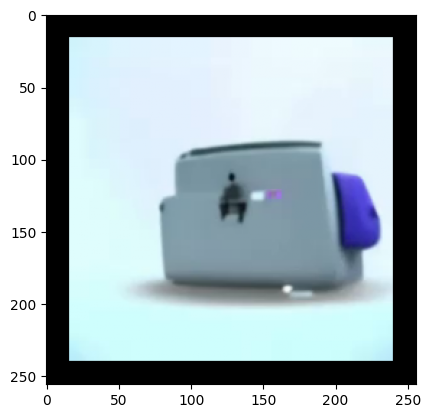

In [45]:
print("First Frame in main:\n ")
plt.imshow(main[0])
plt.show

First Frame in left:
 


<function matplotlib.pyplot.show(close=None, block=None)>

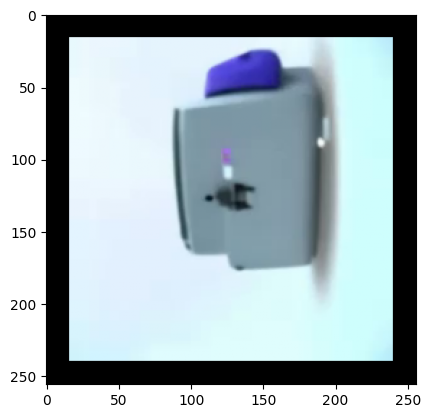

In [46]:
print("First Frame in left:\n ")
plt.imshow(left[0])
plt.show

First Frame in right:
 


<function matplotlib.pyplot.show(close=None, block=None)>

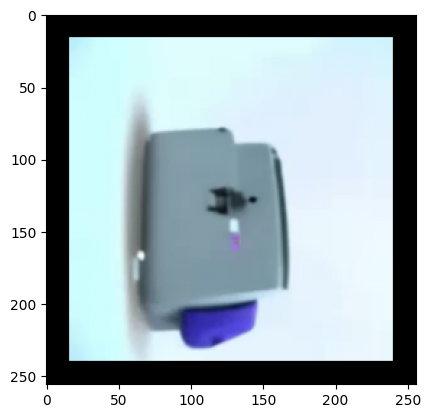

In [47]:
print("First Frame in right:\n ")
plt.imshow(right[0])
plt.show

First Frame in horizontal:
 


<function matplotlib.pyplot.show(close=None, block=None)>

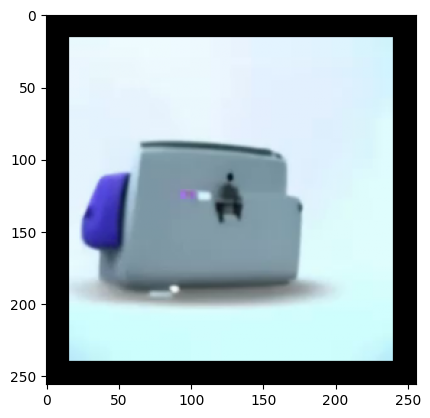

In [48]:
print("First Frame in horizontal:\n ")
plt.imshow(horizontal[0])
plt.show

First Frame in vertical:
 


<function matplotlib.pyplot.show(close=None, block=None)>

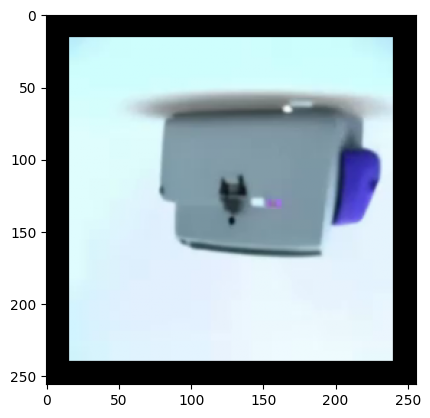

In [49]:
print("First Frame in vertical:\n ")
plt.imshow(vertical[0])
plt.show

# **Organize Dataset**

In [ ]:
Fake_main_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Fake*main.npy")
Fake_main_arr_datapath.sort()

Fake_left_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Fake*left.npy")
Fake_left_arr_datapath.sort()

Fake_right_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Fake*right.npy")
Fake_right_arr_datapath.sort()

Fake_horizontal_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Fake*horizontal.npy")
Fake_horizontal_arr_datapath.sort()

Fake_vertical_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Fake*vertical.npy")
Fake_vertical_arr_datapath.sort()

Real_main_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Real*main.npy")
Real_main_arr_datapath.sort()

Real_left_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Real*left.npy")
Real_left_arr_datapath.sort()

Real_right_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Real*right.npy")
Real_right_arr_datapath.sort()

Real_horizontal_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Real*horizontal.npy")
Real_horizontal_arr_datapath.sort()

Real_vertical_arr_datapath=glob.glob("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data/Real*vertical.npy")
Real_vertical_arr_datapath.sort()

In [ ]:
len(Fake_main_arr_datapath),len(Fake_left_arr_datapath),len(Fake_right_arr_datapath),len(Fake_horizontal_arr_datapath),len(Fake_vertical_arr_datapath),len(Real_main_arr_datapath),len(Real_left_arr_datapath),len(Real_right_arr_datapath),len(Real_horizontal_arr_datapath),len(Real_vertical_arr_datapath)

(492, 492, 492, 492, 492, 500, 500, 500, 500, 500)

In [ ]:
Target,Main,Right,Left,Horizontal,Vertical=[],[],[],[],[],[]
for item in Fake_main_arr_datapath:
    Target.append(0)
    Main.append(item)
for item in Fake_left_arr_datapath:
    Left.append(item)
for item in Fake_right_arr_datapath:
    Right.append(item)
for item in Fake_horizontal_arr_datapath:
    Horizontal.append(item)
for item in Fake_vertical_arr_datapath:
    Vertical.append(item)
for item in Real_main_arr_datapath:
    Target.append(1)
    Main.append(item)
for item in Real_left_arr_datapath:
    Left.append(item)
for item in Real_right_arr_datapath:
    Right.append(item)
for item in Real_horizontal_arr_datapath:
    Horizontal.append(item)
for item in Real_vertical_arr_datapath:
    Vertical.append(item)

In [ ]:
len(Target), len(Main), len(Right), len(Left), len(Horizontal), len(Vertical)

(100, 100, 100, 100, 100, 100)

In [ ]:
Data_dir_set = dict()
Data_dir_set["Target"]=Target
Data_dir_set["Main"]=Main
Data_dir_set["Right"]=Right
Data_dir_set["Left"]=Left
Data_dir_set["Horizontal"]=Horizontal
Data_dir_set["Vertical"]=Vertical
Data_dir_set = pd.DataFrame(Data_dir_set)
Data_dir_set = Data_dir_set.sample(frac=1).reset_index(drop=True)

In [ ]:
Data_dir_set.to_excel("/content/drive/MyDrive/DeepFake Detection Project/Datasets/Data_50_dir_set.xlsx")

In [ ]:
original_list, left_list, right_list, horizontal_list, vertical_list, total_list = [],[],[],[],[],[]

In [ ]:
XT,X0,X1,X2,X3,X4=list(),list(),list(),list(),list(),list()

In [ ]:
y_serial,y_parallel=list(),list()

In [ ]:
#Real_data_dirs
#OpenSora_data_dirs
for video_file in Real_data_dirs:
    original, left, right, horizontal, vertical = process_video(video_file)
    for image in list([original, left, right, horizontal, vertical]):
        total_list.append(np.array(image))
    original_list.append(original)
    left_list.append(left)
    right_list.append(right)
    horizontal_list.append(horizontal)
    vertical_list.append(vertical)

In [ ]:
total_list = [item for item in total_list if item.shape == (10, 280, 280, 3)]
original_list = [item for item in original_list if item.shape == (10, 280, 280, 3)]
left_list = [item for item in left_list if item.shape == (10, 280, 280, 3)]
right_list = [item for item in right_list if item.shape == (10, 280, 280, 3)]
horizontal_list = [item for item in horizontal_list if item.shape == (10, 280, 280, 3)]
vertical_list = [item for item in vertical_list if item.shape == (10, 280, 280, 3)]

In [ ]:

for i in range(0,len(total_list)):
    XT.append(total_list[i])
for i in range(0,len(original_list)):
    X0.append(original_list[i])
    X1.append(left_list[i])
    X2.append(right_list[i])
    X3.append(horizontal_list[i])
    X4.append(vertical_list[i])

In [ ]:
for i in range(0,len(total_list)):
    y_serial.append(1)
for i in range(0,len(original_list)):
    y_parallel.append(1)

In [ ]:
len(y_serial),len(y_parallel)

(1000, 200)

In [ ]:
len(total_list),len(original_list),len(left_list),len(right_list),len(horizontal_list),len(vertical_list)

(500, 100, 100, 100, 100, 100)

In [ ]:
np.array(XT).shape, np.array(X0).shape, np.array(y_serial).shape, np.array(y_parallel).shape

((1000, 10, 280, 280, 3), (200, 10, 280, 280, 3), (1000,), (200,))

In [ ]:
XT=np.array(XT)
X0=np.array(X0)
X1=np.array(X1)
X2=np.array(X2)
X3=np.array(X3)
X4=np.array(X4)
y_serial=np.array(y_serial)
y_parallel=np.array(y_parallel)

# **Train Test Split**

In [ ]:
XT_train, XT_test, y_serial_train, y_serial_test = train_test_split(XT, y_serial, test_size=0.2, random_state=42)

In [ ]:
X0_train, X0_test, X1_train, X1_test, X2_train, X2_test, X3_train, X3_test, X4_train, X4_test, y_parallel_train, y_parallel_test = train_test_split(X0, X1, X2, X3, X4, y_parallel, test_size=0.2, random_state=42)

# **Convert and Save as Np Arrays**

In [ ]:
save_dir = "/content/drive/MyDrive/DeepFake Detection Project/Datasets/Numpy_directory/Curated_large/"
os.makedirs(save_dir, exist_ok=True)

np.save(save_dir+"XT_train.npy", XT_train)
np.save(save_dir+"XT_test.npy", XT_test)
np.save(save_dir+"X0_train.npy", X0_train)
np.save(save_dir+"X0_test.npy", X0_test)
np.save(save_dir+"X1_train.npy", X1_train)
np.save(save_dir+"X1_test.npy", X1_test)
np.save(save_dir+"X2_train.npy", X2_train)
np.save(save_dir+"X2_test.npy", X2_test)
np.save(save_dir+"X3_train.npy", X3_train)
np.save(save_dir+"X3_test.npy", X3_test)
np.save(save_dir+"X4_train.npy", X4_train)
np.save(save_dir+"X4_test.npy", X4_test)
np.save(save_dir+"y_serial_train.npy", y_serial_train)
np.save(save_dir+"y_serial_test.npy", y_serial_test)
np.save(save_dir+"y_parallel_train.npy", y_parallel_train)
np.save(save_dir+"y_parallel_test.npy", y_parallel_test)